# Credit scorecard on the "Give Me Some Credit" dataset

In this notebook I build a credit scorecard. The idea is to estimate the probability that a borrower
defaults (the PD) and then convert it into a score, a bit like a credit score.

Data: Kaggle "Give Me Some Credit" (`cs-training.csv`, 150,000 borrowers).
Target: `SeriousDlqin2yrs`, equal to 1 if the borrower was 90 days or more past due within 2 years (a "bad"), 0 otherwise (a "good").

Steps:
1. Load the data and look at the default rate
2. Clean missing values and outliers
3. Stratified train/test split
4. Bins, Weight of Evidence (WoE) and Information Value (IV)
5. Replace the raw values by WoE
6. Logistic regression
7. Convert the model into a points scorecard (base score 600, odds 50:1, PDO 20)
8. Evaluate on the test set (AUC, Gini, KS, score distribution, calibration)
9. Save the scorecard for the Streamlit app
10. Limits

Words used in the notebook:
- PD: probability of default.
- Good / bad: a borrower who did not default / who defaulted.
- Odds: number of goods divided by number of bads.
- WoE: how much safer or riskier a group of borrowers is compared with the average.
- IV: how useful a variable is to separate goods from bads.
- PDO (points to double the odds): the number of points that doubles the good:bad odds.

## 1. Loading the data and the default rate

I load the file and compute the share of borrowers who defaulted. This default rate is the baseline for the whole project.
It is also low, so the data is imbalanced: a model that says "nobody defaults" would already be right most of the time, which is why accuracy is not the right metric here.

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
TARGET = "SeriousDlqin2yrs"
os.makedirs("figures", exist_ok=True)

In [2]:
df = pd.read_csv("data/cs-training.csv")
df = df.drop(columns="Unnamed: 0")   # just a row number

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
default_rate = df[TARGET].mean()
print(f"Default rate: {default_rate:.2%}")
print(df[TARGET].value_counts().rename({0: "good (0)", 1: "bad (1)"}))

Default rate: 6.68%
SeriousDlqin2yrs
good (0)    139974
bad (1)      10026
Name: count, dtype: int64


## 2. Missing values and outliers

Real data has gaps and errors. If I leave them in, the model learns from nonsense (for example that an age of 0 means something).
First I count the missing values and look at the extremes.

In [4]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct_missing"] = (missing["n_missing"] / len(df) * 100).round(2)
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


In [5]:
df.describe(percentiles=[0.01, 0.5, 0.99]).T[["min", "1%", "50%", "99%", "max"]]

,min,1%,50%,99%,max
SeriousDlqin2yrs,0.0,0.0,0.000000,1.000000,1.0
RevolvingUtilizationOfUnsecuredLines,0.0,0.0,0.154181,1.092956,50708.0
age,0.0,24.0,52.000000,87.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,0.0,0.0,0.000000,4.000000,98.0
DebtRatio,0.0,0.0,0.366508,4979.040000,329664.0
MonthlyIncome,0.0,0.0,5400.000000,25000.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,0.0,0.0,8.000000,24.000000,58.0
NumberOfTimes90DaysLate,0.0,0.0,0.000000,3.000000,98.0
NumberRealEstateLoansOrLines,0.0,0.0,1.000000,4.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,0.0,0.0,0.000000,2.000000,98.0


What stands out:
- `age` has a minimum of 0, which is impossible for a borrower.
- The three "number of times past due" columns go up to 98. Nobody is 98 times late, so these look like special codes.
- `RevolvingUtilizationOfUnsecuredLines` goes up to 50,708 although it is a ratio that should be around 0 to 1.
- `DebtRatio` goes up to 329,664 while the median is 0.37.
- `MonthlyIncome` is missing for about 20% of borrowers and `NumberOfDependents` for about 2.6%.

Before deciding what to do with the special codes and the debt ratio, I check them.

In [6]:
# rows with the 96/98 code in "90 days late"
special = df["NumberOfTimes90DaysLate"] >= 96
print("Rows with the 96/98 code:", special.sum())
print(f"Their default rate: {df.loc[special, TARGET].mean():.1%} (overall: {default_rate:.1%})")

# where do the huge debt ratios come from?
huge_ratio = df["DebtRatio"] > 5
print("\nRows with DebtRatio > 5:", huge_ratio.sum())
print(f"Share of them with missing income: {df.loc[huge_ratio, 'MonthlyIncome'].isna().mean():.0%}")
print(f"Their default rate: {df.loc[huge_ratio, TARGET].mean():.1%}")

Rows with the 96/98 code: 269
Their default rate: 54.6% (overall: 6.7%)

Rows with DebtRatio > 5: 29646
Share of them with missing income: 92%
Their default rate: 5.5%


So the 96/98 rows are very risky (about 55% default), and I do not want to throw that information away. I will cap the counts at 10 instead of deleting those rows.

For `DebtRatio`, almost all the huge values are borrowers with no income. It looks like the column contains a raw debt amount there instead of a ratio.
A value above 5 (500% of income) is not a usable ratio, so I set it to missing.

Cleaning rules:
- drop rows with age under 18
- cap the three past-due counts at 10
- cap credit utilization at 2
- set `DebtRatio` above 5 to missing

These rules use fixed thresholds and do not compute anything from the data (no mean or median), so applying them before the split does not leak information from the test set.
Everything that learns from the data (median, bins, WoE, model) comes after the split and uses the train set only.

In [7]:
n_before = len(df)

# 1) impossible ages
df = df[df["age"] >= 18].copy()

# 2) past-due counts capped at 10
past_due_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]
for col in past_due_cols:
    df[col] = df[col].clip(upper=10)

# 3) utilization capped at 2
df["RevolvingUtilizationOfUnsecuredLines"] = df["RevolvingUtilizationOfUnsecuredLines"].clip(upper=2)

# 4) debt ratio above 5 is not a real ratio, so set it to missing
df.loc[df["DebtRatio"] > 5, "DebtRatio"] = np.nan

print("Rows removed:", n_before - len(df))
print("DebtRatio now missing:", df["DebtRatio"].isna().sum())
print(f"Default rate after cleaning: {df[TARGET].mean():.2%}")

Rows removed: 1
DebtRatio now missing: 29646
Default rate after cleaning: 6.68%


## 3. Train/test split

I keep 70% of the borrowers to build the model (train) and 30% to test it (test).
The test set plays the role of new customers the model has never seen, so it gives an honest idea of the performance.

The split is stratified, which means both parts keep the same default rate. Without it, defaults being rare, one part could end up with noticeably fewer of them.

Data leakage means letting information from the test set influence the model. To avoid it, I fit everything on the train set and only apply it to the test set.
The first example is the median used to fill the missing `NumberOfDependents`.

In [8]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, f"default rate = {y_train.mean():.2%}")
print("Test :", X_test.shape, f"default rate = {y_test.mean():.2%}")

Train: (104999, 10) default rate = 6.68%
Test : (45000, 10) default rate = 6.68%


In [9]:
# median computed on train only, then used on both sets
dependents_median = X_train["NumberOfDependents"].median()
X_train["NumberOfDependents"] = X_train["NumberOfDependents"].fillna(dependents_median)
X_test["NumberOfDependents"] = X_test["NumberOfDependents"].fillna(dependents_median)

print("Median used:", dependents_median)
print("Missing values left in train:")
print(X_train.isna().sum()[lambda s: s > 0])

Median used: 0.0
Missing values left in train:
DebtRatio        20670
MonthlyIncome    20726
dtype: int64


`MonthlyIncome` and `DebtRatio` still have missing values on purpose. In the next step "missing" becomes its own group,
because not having a value can say something about the borrower.

## 4. Bins, Weight of Evidence (WoE) and Information Value (IV)

Binning means cutting a variable into a few groups, for example age into "30 or less", "30 to 40", "40 to 50" and so on.
It handles outliers (a 109 year old simply falls in "over 70") and makes non-linear effects visible.

For each bin I compute:
- `dist_good`: the share of all goods that are in this bin
- `dist_bad`: the share of all bads that are in this bin
- WoE = ln(`dist_good` / `dist_bad`)

A positive WoE means the bin contains relatively more goods than average (safer). A negative WoE means more bads (riskier). Zero means average.

The Information Value of a variable adds up all its bins: IV = sum of (`dist_good` - `dist_bad`) x WoE.
The usual rule of thumb:
- under 0.02: useless
- 0.02 to 0.1: weak
- 0.1 to 0.3: medium
- 0.3 to 0.5: strong
- above 0.5: suspiciously strong, worth checking for leakage

The bins and WoE values are computed on the train set only, then applied to the test set.

In [10]:
# Bin edges for each variable. I picked them by looking at the default rate per bin on the train set.
# A bin is (lower, upper]; the first bin is "<= first edge" and the last one is "> last edge".
bin_edges = {
    "RevolvingUtilizationOfUnsecuredLines": [0.05, 0.15, 0.3, 0.5, 0.7, 0.9, 1.0],
    "age": [30, 40, 50, 60, 70],
    "DebtRatio": [0.4, 0.5, 0.7, 1.0],
    "MonthlyIncome": [3000, 5000, 6500, 8000, 10000],
    "NumberOfOpenCreditLinesAndLoans": [1, 3, 5, 13],
    "NumberRealEstateLoansOrLines": [0, 2],
    "NumberOfDependents": [0, 1, 2],
    "NumberOfTime30-59DaysPastDueNotWorse": [0, 1, 2, 5],
    "NumberOfTimes90DaysLate": [0, 1, 2],
    "NumberOfTime60-89DaysPastDueNotWorse": [0, 1, 2],
}

In [11]:
def make_labels(edges):
    # [30, 40, 50] -> ["<= 30", "(30, 40]", "(40, 50]", "> 50"]
    labels = [f"<= {edges[0]:g}"]
    for low, high in zip(edges[:-1], edges[1:]):
        labels.append(f"({low:g}, {high:g}]")
    labels.append(f"> {edges[-1]:g}")
    return labels


def assign_bins(series, edges):
    # put each value in its bin, missing values go to a bin called "Missing"
    cut = pd.cut(series, bins=[-np.inf] + edges + [np.inf], labels=make_labels(edges))
    return cut.astype(object).fillna("Missing")


def woe_table(bins, y, edges):
    # WoE / IV table for one variable
    t = pd.DataFrame({"bin": bins.values, "is_bad": y.values})
    t = t.groupby("bin")["is_bad"].agg(total="count", bad="sum")
    t["good"] = t["total"] - t["bad"]

    # keep the bins in their natural order
    order = [b for b in make_labels(edges) + ["Missing"] if b in t.index]
    t = t.loc[order]

    t["pct_of_total"] = t["total"] / t["total"].sum()
    t["default_rate"] = t["bad"] / t["total"]

    # +0.5 so that we never take the log of 0
    good_smooth = t["good"] + 0.5
    bad_smooth = t["bad"] + 0.5
    t["dist_good"] = good_smooth / good_smooth.sum()
    t["dist_bad"] = bad_smooth / bad_smooth.sum()

    t["woe"] = np.log(t["dist_good"] / t["dist_bad"])
    t["iv_part"] = (t["dist_good"] - t["dist_bad"]) * t["woe"]
    return t

In [12]:
woe_tables = {}
iv_values = {}

for var, edges in bin_edges.items():
    bins_train = assign_bins(X_train[var], edges)
    table = woe_table(bins_train, y_train, edges)
    woe_tables[var] = table
    iv_values[var] = table["iv_part"].sum()

iv_summary = pd.Series(iv_values, name="IV").sort_values(ascending=False).to_frame()
iv_summary["power"] = pd.cut(
    iv_summary["IV"], [-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
    labels=["useless", "weak", "medium", "strong", "suspicious"],
)
iv_summary.round(4)

,IV,power
RevolvingUtilizationOfUnsecuredLines,1.1397,suspicious
NumberOfTimes90DaysLate,0.8921,suspicious
NumberOfTime30-59DaysPastDueNotWorse,0.7392,suspicious
NumberOfTime60-89DaysPastDueNotWorse,0.6009,suspicious
age,0.2254,medium
NumberOfOpenCreditLinesAndLoans,0.0974,weak
MonthlyIncome,0.0753,weak
DebtRatio,0.0721,weak
NumberRealEstateLoansOrLines,0.0554,weak
NumberOfDependents,0.0329,weak


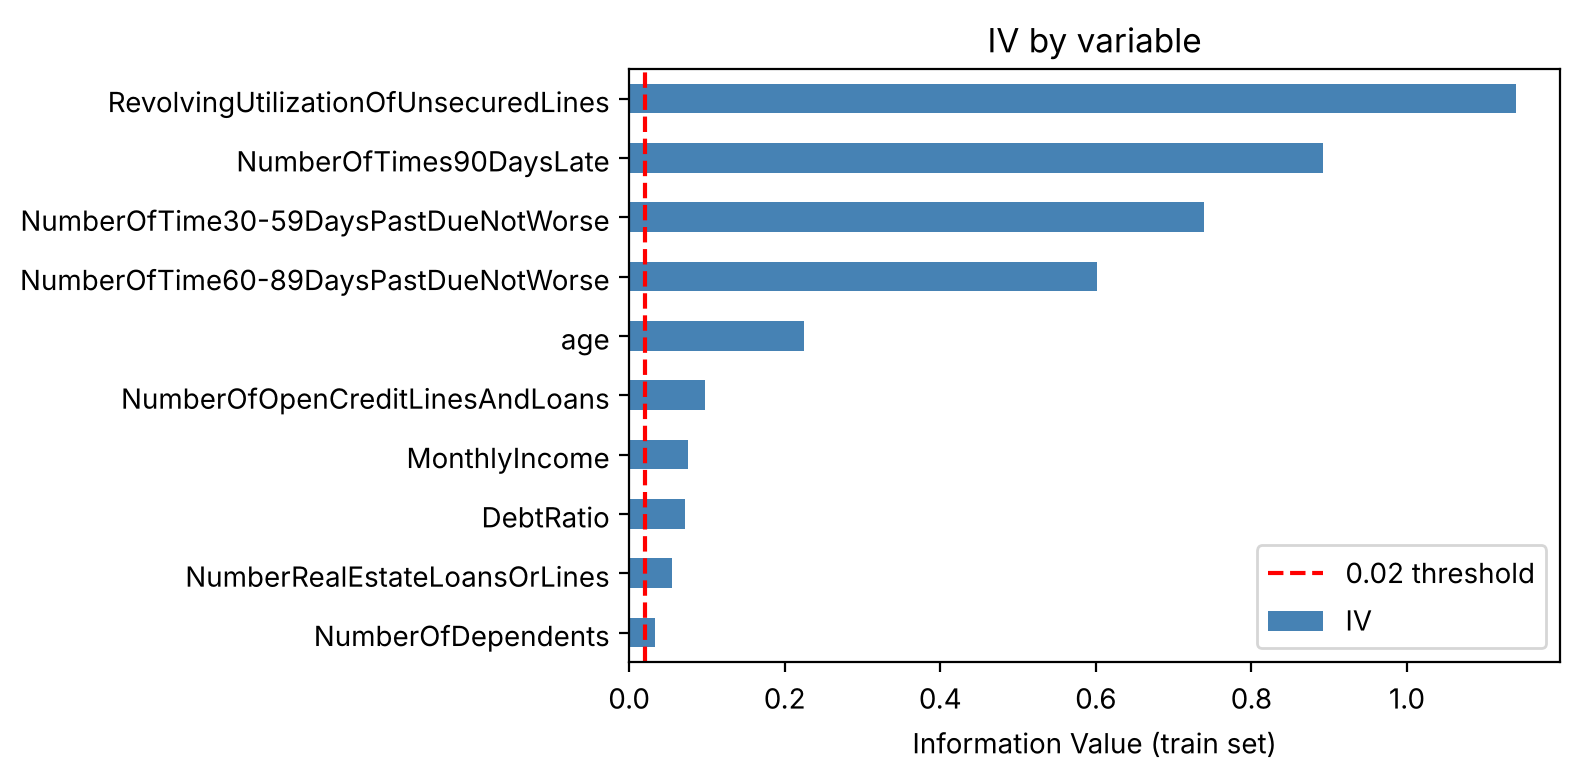

In [13]:
ax = iv_summary["IV"].sort_values().plot(kind="barh", figsize=(8, 4), color="steelblue")
ax.axvline(0.02, color="red", linestyle="--", label="0.02 threshold")
ax.set_xlabel("Information Value (train set)")
ax.set_title("IV by variable")
ax.legend()
plt.tight_layout()
plt.savefig("figures/iv_ranking.png", dpi=120)
plt.show()

In [14]:
show_cols = ["total", "pct_of_total", "bad", "default_rate", "woe", "iv_part"]
for var in iv_summary.index:
    print(f"\n=== {var}   (IV = {iv_values[var]:.4f}) ===")
    print(woe_tables[var][show_cols].round(4).to_string())


=== RevolvingUtilizationOfUnsecuredLines   (IV = 1.1397) ===
              total  pct_of_total   bad  default_rate     woe  iv_part
bin                                                                   
<= 0.05       33683        0.3208   597        0.0177  1.3784   0.3481
(0.05, 0.15]  18405        0.1753   407        0.0221  1.1522   0.1448
(0.15, 0.3]   12795        0.1219   418        0.0327  0.7512   0.0501
(0.3, 0.5]    11187        0.1065   648        0.0579  0.1525   0.0023
(0.5, 0.7]     7919        0.0754   784        0.0990 -0.4280   0.0166
(0.7, 0.9]     7005        0.0667  1043        0.1489 -0.8929   0.0784
(0.9, 1]      11675        0.1112  2260        0.1936 -1.2090   0.2730
> 1            2330        0.0222   861        0.3695 -2.1018   0.2263

=== NumberOfTimes90DaysLate   (IV = 0.8921) ===
        total  pct_of_total   bad  default_rate     woe  iv_part
bin                                                             
<= 0    99093        0.9438  4558        0.0460  

How to read a table: in the utilization table the default rate goes up from the first bin to the last one, and the WoE goes down the opposite way.
This kind of monotonic pattern is what I want, because it is easy to explain.

What the IV ranking shows:
- Strongest: credit utilization (IV about 1.14) and the three past-due counts (90+ days about 0.89, 30-59 days about 0.74, 60-89 days about 0.60).
- Medium: `age` (about 0.23).
- Weak: open credit lines (about 0.10), income (about 0.08), debt ratio (about 0.07), real-estate loans (about 0.06), dependents (about 0.03).
- All ten variables are above 0.02, so none is dropped.

A few things I noticed in the bins:
- Utilization: the default rate goes from about 1.8% (utilization of 5% or less) to about 37% (above 100%).
- 90+ days late: about 4.6% for borrowers who were never late, 33.7% after one time and about 61% after three times or more.
- Age: about 11.3% for 30 or less and about 2.4% above 70.
- Borrowers with missing income or missing debt ratio default about 5.5% and 5.4% of the time, which is below the 6.7% average. Missing does not mean risky here, which is a good reason to keep it as its own bin.
- Real-estate loans are not monotonic: 0 loans gives 8.3%, 1 to 2 loans gives 5.4% and more than 2 gives 8.6%.

Four variables have an IV above 0.5, which the rule of thumb flags. They are credit utilization and the past-due history, which are real behavior signals
and describe the past of the borrower, so being this strong is plausible. But the file alone does not prove they were all measured before the 2-year window, so this is something to check with the data owner in a real project.

In [15]:
# keep the variables with IV >= 0.02
selected_vars = iv_summary.index[iv_summary["IV"] >= 0.02].tolist()
dropped_vars = [v for v in iv_summary.index if v not in selected_vars]

print("Selected variables:", len(selected_vars))
for v in selected_vars:
    print("  -", v)
print("Dropped (IV < 0.02):", dropped_vars)

Selected variables: 10
  - RevolvingUtilizationOfUnsecuredLines
  - NumberOfTimes90DaysLate
  - NumberOfTime30-59DaysPastDueNotWorse
  - NumberOfTime60-89DaysPastDueNotWorse
  - age
  - NumberOfOpenCreditLinesAndLoans
  - MonthlyIncome
  - DebtRatio
  - NumberRealEstateLoansOrLines
  - NumberOfDependents
Dropped (IV < 0.02): []


## 5. Replacing the raw values by their WoE

Each value is replaced by the WoE of its bin. The test set uses the WoE values learned on the train set.
After this step all the variables are on the same scale, and the model is a simple combination of them.
I also check the correlation between the new variables, because very correlated variables make the logistic regression coefficients unstable.

In [16]:
# {variable: {bin: WoE}}
woe_maps = {var: woe_tables[var]["woe"].to_dict() for var in selected_vars}


def to_woe(X):
    out = pd.DataFrame(index=X.index)
    for var in selected_vars:
        bins = assign_bins(X[var], bin_edges[var])
        out[var] = bins.map(woe_maps[var])
    return out


X_train_woe = to_woe(X_train)
X_test_woe = to_woe(X_test)

# every value should have found a WoE
print("NaN in train WoE:", X_train_woe.isna().sum().sum())
print("NaN in test WoE :", X_test_woe.isna().sum().sum())
X_train_woe.head()

NaN in train WoE: 0
NaN in test WoE : 0


,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,age,NumberOfOpenCreditLinesAndLoans,MonthlyIncome,DebtRatio,NumberRealEstateLoansOrLines,NumberOfDependents
138986,1.378360,0.395951,0.532157,0.289502,-0.216344,0.184714,0.211259,0.227108,0.231538,0.149077
63964,1.378360,0.395951,0.532157,0.289502,-0.417066,0.053541,-0.340974,-0.039579,0.231538,-0.108065
46077,1.378360,0.395951,0.532157,0.289502,-0.417066,0.184714,-0.231138,-0.336065,0.231538,0.149077
83031,1.378360,0.395951,-0.884293,0.289502,-0.574775,0.184714,-0.056420,0.133306,-0.233327,0.149077
11184,-0.427975,0.395951,0.532157,0.289502,-0.417066,0.184714,-0.056420,-0.336065,-0.275742,-0.108065


In [17]:
corr = X_train_woe.corr().round(2)
display(corr)

# the 3 most correlated pairs
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print("Most correlated pairs:")
print(upper.stack().sort_values(ascending=False).head(3))

,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,age,NumberOfOpenCreditLinesAndLoans,MonthlyIncome,DebtRatio,NumberRealEstateLoansOrLines,NumberOfDependents
RevolvingUtilizationOfUnsecuredLines,1.00,0.29,0.27,0.23,0.27,0.24,0.11,0.13,0.09,0.10
NumberOfTimes90DaysLate,0.29,1.00,0.29,0.35,0.10,0.18,0.08,-0.00,0.08,0.03
NumberOfTime30-59DaysPastDueNotWorse,0.27,0.29,1.00,0.32,0.10,-0.00,0.03,0.08,0.00,0.07
NumberOfTime60-89DaysPastDueNotWorse,0.23,0.35,0.32,1.00,0.08,0.07,0.05,0.03,0.04,0.03
age,0.27,0.10,0.10,0.08,1.00,0.07,0.09,0.07,0.00,0.26
NumberOfOpenCreditLinesAndLoans,0.24,0.18,-0.00,0.07,0.07,1.00,0.10,-0.10,0.28,-0.09
MonthlyIncome,0.11,0.08,0.03,0.05,0.09,0.10,1.00,0.26,0.14,-0.09
DebtRatio,0.13,-0.00,0.08,0.03,0.07,-0.10,0.26,1.00,-0.14,0.10
NumberRealEstateLoansOrLines,0.09,0.08,0.00,0.04,0.00,0.28,0.14,-0.14,1.00,-0.13
NumberOfDependents,0.10,0.03,0.07,0.03,0.26,-0.09,-0.09,0.10,-0.13,1.00


Most correlated pairs:
NumberOfTimes90DaysLate               NumberOfTime60-89DaysPastDueNotWorse    0.35
NumberOfTime30-59DaysPastDueNotWorse  NumberOfTime60-89DaysPastDueNotWorse    0.32
NumberOfTimes90DaysLate               NumberOfTime30-59DaysPastDueNotWorse    0.29
dtype: float64


The correlations are low to moderate. The highest one is 0.35, between the 90+ days and the 60-89 days late variables, which makes sense because they measure similar behavior.
Nothing needs to be removed.

## 6. Logistic regression

Logistic regression predicts the probability of default with:

ln(PD / (1 - PD)) = b0 + b1 x WoE1 + b2 x WoE2 + ...

The b values are the coefficients, found by the algorithm from the train data. It is the standard model for scorecards because each variable has a single coefficient, so it is easy to explain.

Since WoE is high for safe bins, all coefficients should come out negative: more WoE means less risk.
A positive one would be suspicious and often comes from correlated variables.

I do not use class weights. Re-balancing the rare defaults would distort the predicted probabilities, and here I care about the PD value itself, not only the ranking.
`C=np.inf` turns off regularization, so it is the plain logistic regression.

In [18]:
model = LogisticRegression(C=np.inf, max_iter=1000)
model.fit(X_train_woe, y_train)

coefs = pd.Series(model.coef_[0], index=selected_vars, name="coefficient")
print("Intercept (b0):", round(model.intercept_[0], 4))
print()
print(coefs.round(4).to_frame())
print()
print("All coefficients negative?", bool((coefs < 0).all()))

Intercept (b0): -2.604

                                      coefficient
RevolvingUtilizationOfUnsecuredLines      -0.6118
NumberOfTimes90DaysLate                   -0.5307
NumberOfTime30-59DaysPastDueNotWorse      -0.4956
NumberOfTime60-89DaysPastDueNotWorse      -0.3729
age                                       -0.3744
NumberOfOpenCreditLinesAndLoans           -0.0983
MonthlyIncome                             -0.0727
DebtRatio                                 -0.9047
NumberRealEstateLoansOrLines              -0.5870
NumberOfDependents                        -0.2798

All coefficients negative? True


All ten coefficients are negative, as expected.
- Utilization (-0.61), the past-due counts (-0.37 to -0.53) and age (-0.37) have a lot of weight.
- `DebtRatio` has the largest coefficient (-0.90) even though its IV is low (0.07). I think this comes from its overlap with `MonthlyIncome`: they are correlated and their "Missing" bins flag almost the same borrowers, so the model shares the signal between them.
  With correlated variables a single coefficient should not be over-interpreted.
- `NumberOfOpenCreditLinesAndLoans` (-0.10) and `MonthlyIncome` (-0.07) have small coefficients, so they barely move the score.

## 7. Points-based scorecard

A probability is not very practical, so I convert the model into points. I fix:
- a base score of 600 at odds of 50:1 (50 goods for 1 bad, so PD = 1/51, about 1.96%)
- PDO = 20: every +20 points doubles the good:bad odds

Formulas:
- Factor = PDO / ln(2)
- Offset = base score - Factor x ln(base odds)
- Score = Offset + Factor x ln(odds_good), where odds_good = (1 - PD) / PD = -(b0 + sum of bi x WoEi)

Writing this per variable gives the points of each bin:

points = -bi x WoE x Factor + (Offset - b0 x Factor) / n, with n the number of variables.

The final score is the sum of the points of the bins the borrower falls in. I round the points to integers, as a real scorecard would.
The advantage is that the score can be explained variable by variable and computed without any model.

In [19]:
BASE_SCORE = 600
BASE_ODDS = 50
PDO = 20

factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
n_vars = len(selected_vars)
b0 = model.intercept_[0]

print(f"Factor = {factor:.4f}")
print(f"Offset = {offset:.4f}")

Factor = 28.8539
Offset = 487.1229


In [20]:
rows = []
points_maps = {}   # {variable: {bin: points}}

for var in selected_vars:
    table = woe_tables[var]
    points_maps[var] = {}
    for bin_label, row in table.iterrows():
        pts = -coefs[var] * row["woe"] * factor + (offset - b0 * factor) / n_vars
        pts = int(round(pts))
        points_maps[var][bin_label] = pts
        rows.append({
            "variable": var,
            "bin": bin_label,
            "n_borrowers": int(row["total"]),
            "default_rate": round(row["default_rate"], 4),
            "woe": round(row["woe"], 4),
            "points": pts,
        })

points_table = pd.DataFrame(rows)
points_table

,variable,bin,n_borrowers,default_rate,woe,points
0,RevolvingUtilizationOfUnsecuredLines,<= 0.05,33683,0.0177,1.3784,81
1,RevolvingUtilizationOfUnsecuredLines,"(0.05, 0.15]",18405,0.0221,1.1522,77
2,RevolvingUtilizationOfUnsecuredLines,"(0.15, 0.3]",12795,0.0327,0.7512,69
3,RevolvingUtilizationOfUnsecuredLines,"(0.3, 0.5]",11187,0.0579,0.1525,59
4,RevolvingUtilizationOfUnsecuredLines,"(0.5, 0.7]",7919,0.0990,-0.4280,49
5,RevolvingUtilizationOfUnsecuredLines,"(0.7, 0.9]",7005,0.1489,-0.8929,40
6,RevolvingUtilizationOfUnsecuredLines,"(0.9, 1]",11675,0.1936,-1.2090,35
7,RevolvingUtilizationOfUnsecuredLines,> 1,2330,0.3695,-2.1018,19
8,NumberOfTimes90DaysLate,<= 0,99093,0.0460,0.3960,62
9,NumberOfTimes90DaysLate,"(0, 1]",3738,0.3373,-1.9611,26


In [21]:
def compute_score(X):
    # score = sum of the points of each variable
    total = pd.Series(0, index=X.index)
    for var in selected_vars:
        bins = assign_bins(X[var], bin_edges[var])
        total = total + bins.map(points_maps[var])
    return total


def score_to_pd(score):
    # inverse of the score formula
    odds_good = np.exp((score - offset) / factor)
    return 1 / (1 + odds_good)


score_train = compute_score(X_train)
score_test = compute_score(X_test)

print("Score range on train:", score_train.min(), "to", score_train.max())
print("1/51 =", round(1 / 51, 4))
print("PD at score 600 =", round(float(score_to_pd(600)), 4))

Score range on train: 394 to 627
1/51 = 0.0196
PD at score 600 = 0.0196


In [22]:
# does the rounded scorecard give the same result as the model?
pd_model_test = model.predict_proba(X_test_woe)[:, 1]
pd_score_test = score_to_pd(score_test)

print("Mean |PD model - PD scorecard| on test:", round(float(np.mean(np.abs(pd_model_test - pd_score_test))), 5))
print("AUC from model probabilities :", round(roc_auc_score(y_test, pd_model_test), 4))
print("AUC from scorecard points    :", round(roc_auc_score(y_test, -score_test), 4))

Mean |PD model - PD scorecard| on test: 0.00107
AUC from model probabilities : 0.8575
AUC from scorecard points    : 0.8574


More points means safer. Some examples from the table:
- Going from utilization of 5% or less (81 points) to above 100% (19 points) costs 62 points, a bit more than 3 PDOs, so the good:bad odds are divided by about 8 to 9.
- The widest ranges are utilization (19 to 81), 90+ days late (9 to 62), 30-59 days late (18 to 64), age (50 to 68) and debt ratio (40 to 62).
  Income, open credit lines and dependents only move the score by a few points, which matches their small coefficients.
- On the test set the scores go from 404 to 627 with a mean of about 582, and a score of 600 gives a PD of 1.96% as designed.
- Rounding the points changes almost nothing: the PD differs by about 0.001 on average and the AUC is the same to 3 decimals.

## 8. Evaluation on the test set

I measure two different things.

Discrimination is the ability to rank risky borrowers below safe ones:
- AUC: the probability that a random bad gets a lower score than a random good. 0.5 is a coin flip and 1 is perfect.
- Gini = 2 x AUC - 1, the same information on a 0 to 1 scale.
- KS: the largest gap between the cumulative share of bads and of goods along the score. Higher means better separation.

Calibration is whether the PD levels are right: when the model says 10%, do about 10% of those borrowers default?
This matters when the PD value itself is used, for example for provisions (IFRS 9) or capital (IRB).
A model can rank well and still be badly calibrated, so I check both.

I also compute the metrics on train. A big gap between train and test would mean overfitting.

In [23]:
def ks_statistic(y_true, risk_score):
    # largest gap between the ROC curve and the diagonal
    fpr, tpr, _ = roc_curve(y_true, risk_score)
    return float(np.max(tpr - fpr))


results = {}
for name, y_true, score in [("train", y_train, score_train), ("test", y_test, score_test)]:
    risk = -score   # low score = high risk, so I flip the sign
    auc = roc_auc_score(y_true, risk)
    results[name] = {"AUC": auc, "Gini": 2 * auc - 1, "KS": ks_statistic(y_true, risk)}

metrics = pd.DataFrame(results).T
metrics.round(4)

,AUC,Gini,KS
train,0.8575,0.7150,0.5539
test,0.8574,0.7147,0.5617


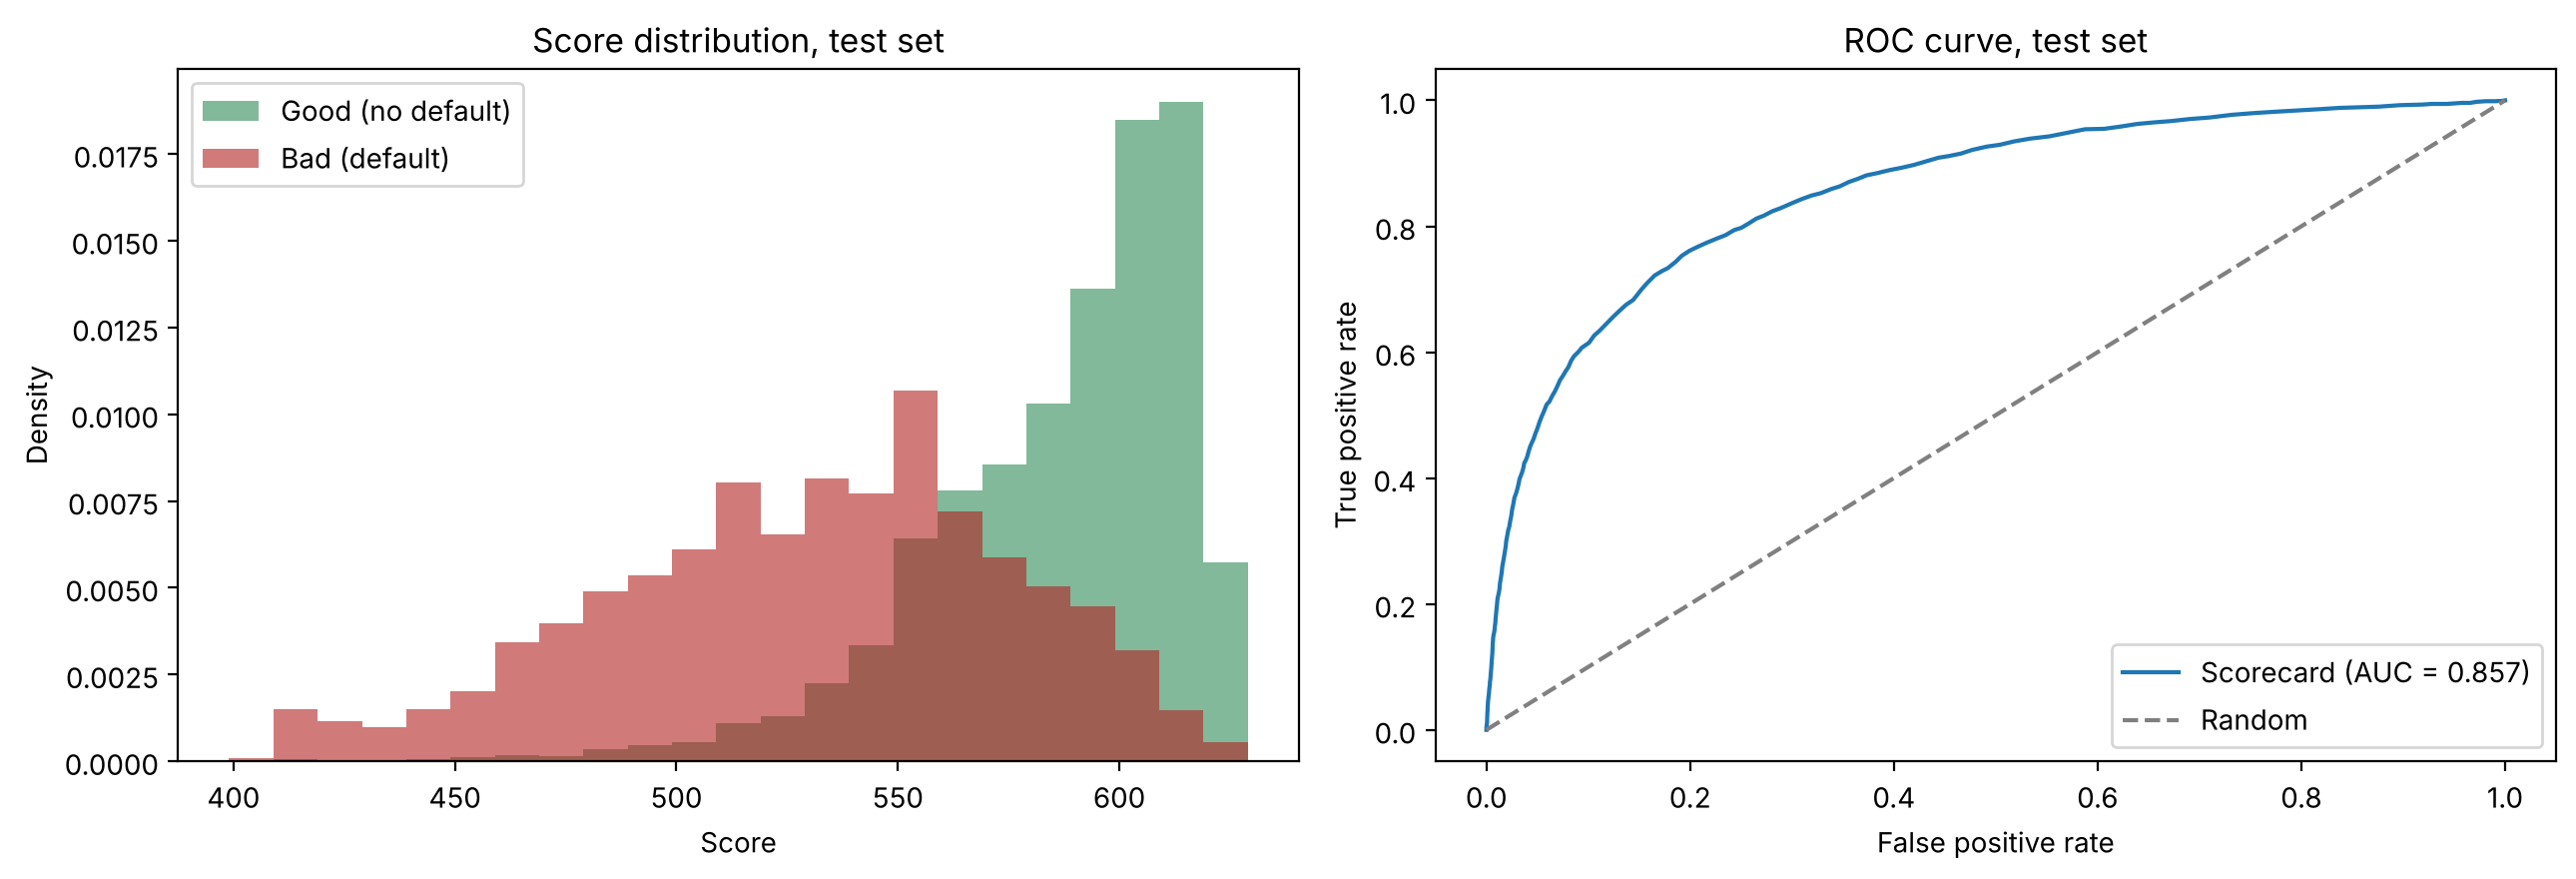

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.arange(score_test.min() - 5, score_test.max() + 10, 10)
axes[0].hist(score_test[y_test == 0], bins=bins, alpha=0.6, density=True, label="Good (no default)", color="seagreen")
axes[0].hist(score_test[y_test == 1], bins=bins, alpha=0.6, density=True, label="Bad (default)", color="firebrick")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Density")
axes[0].set_title("Score distribution, test set")
axes[0].legend()

fpr, tpr, _ = roc_curve(y_test, -score_test)
axes[1].plot(fpr, tpr, label=f"Scorecard (AUC = {results['test']['AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Random")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve, test set")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/score_distribution_and_roc.png", dpi=120)
plt.show()

           n  avg_pd_predicted  observed_default_rate
decile                                               
1       4500            0.0102                 0.0051
2       4500            0.0127                 0.0058
3       4500            0.0152                 0.0100
4       4500            0.0184                 0.0124
5       4500            0.0228                 0.0227
6       4500            0.0302                 0.0269
7       4500            0.0426                 0.0438
8       4500            0.0637                 0.0609
9       4500            0.1018                 0.1187
10      4500            0.3503                 0.3622

Overall: predicted PD = 0.0668 | observed default rate = 0.0668


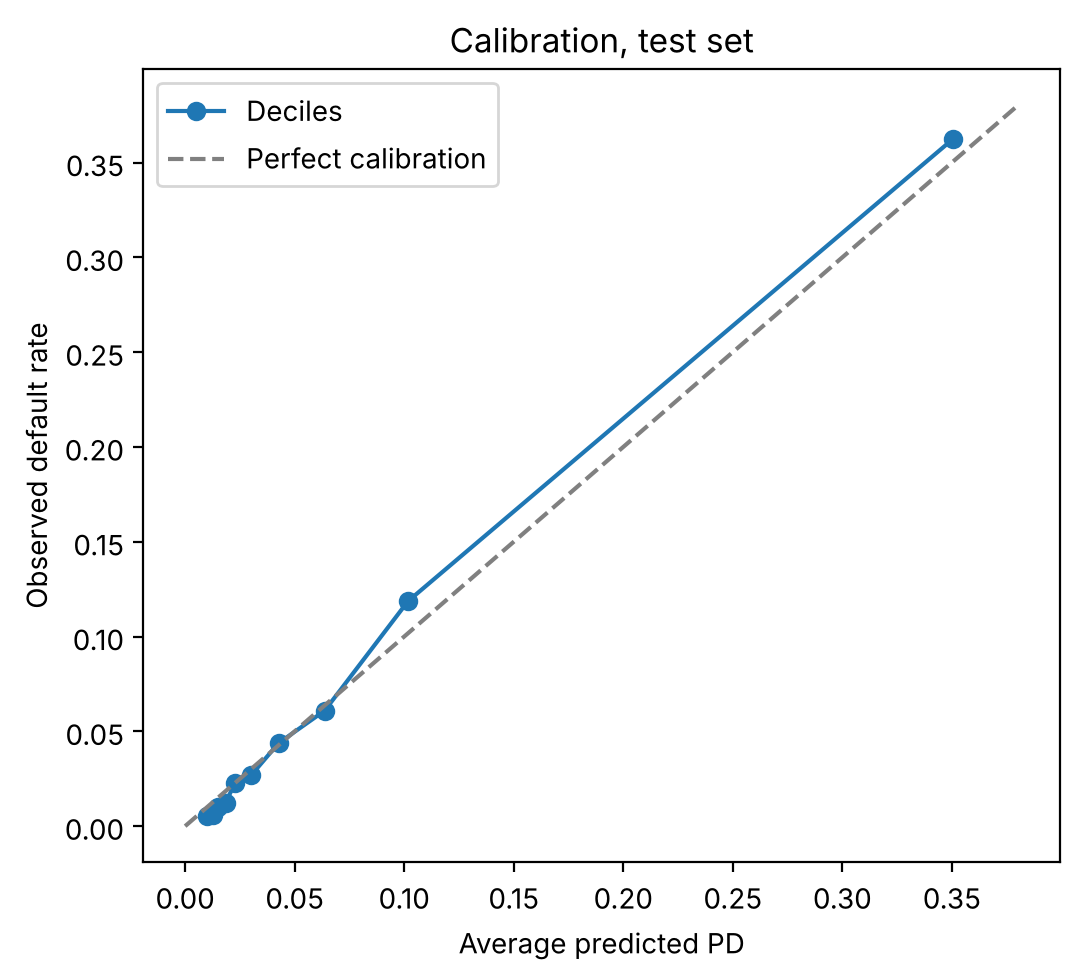

In [25]:
# Calibration: 10 groups of equal size sorted by predicted PD,
# then average predicted PD vs observed default rate in each group
cal = pd.DataFrame({"pd_pred": score_to_pd(score_test), "bad": y_test.values})
cal["decile"] = pd.qcut(cal["pd_pred"].rank(method="first"), 10, labels=False) + 1   # 1 = safest

cal_table = cal.groupby("decile").agg(
    n=("bad", "count"),
    avg_pd_predicted=("pd_pred", "mean"),
    observed_default_rate=("bad", "mean"),
)
print(cal_table.round(4))
print()
print(f"Overall: predicted PD = {cal['pd_pred'].mean():.4f} | observed default rate = {cal['bad'].mean():.4f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(cal_table["avg_pd_predicted"], cal_table["observed_default_rate"], "o-", label="Deciles")
top = max(cal_table["avg_pd_predicted"].max(), cal_table["observed_default_rate"].max()) * 1.05
ax.plot([0, top], [0, top], "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Average predicted PD")
ax.set_ylabel("Observed default rate")
ax.set_title("Calibration, test set")
ax.legend()
plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=120)
plt.show()

In [26]:
# Is the gap in the safest deciles caused by rounding the points? Same table with the unrounded model, on test and train.
for name, X_woe, y_true in [("test", X_test_woe, y_test), ("train", X_train_woe, y_train)]:
    chk = pd.DataFrame({"pd_model": model.predict_proba(X_woe)[:, 1], "bad": y_true.values})
    chk["decile"] = pd.qcut(chk["pd_model"].rank(method="first"), 10, labels=False) + 1
    print(f"\nUnrounded model, {name} set:")
    print(chk.groupby("decile").agg(avg_pd_model=("pd_model", "mean"), observed=("bad", "mean")).round(4).T.to_string())


Unrounded model, test set:
decile            1       2       3       4       5       6       7       8       9       10
avg_pd_model  0.0101  0.0126  0.0150  0.0183  0.0225  0.0297  0.0420  0.0626  0.1002  0.3480
observed      0.0058  0.0044  0.0107  0.0124  0.0213  0.0278  0.0451  0.0598  0.1189  0.3622

Unrounded model, train set:
decile            1       2      3       4       5       6       7       8       9       10
avg_pd_model  0.0101  0.0126  0.015  0.0183  0.0226  0.0299  0.0425  0.0637  0.1022  0.3512
observed      0.0051  0.0066  0.010  0.0114  0.0170  0.0278  0.0480  0.0684  0.1166  0.3574


Results:
- Discrimination on the test set: AUC = 0.857, Gini = 0.715, KS = 0.562. Train and test are almost the same (AUC 0.8575 and 0.8574), so there is no sign of overfitting.
- The bads (red) are mostly at lower scores than the goods (green). The two overlap in the middle, which is normal in credit scoring.
- Calibration: on average the predicted PD (6.68%) is equal to the observed default rate (6.68%). In the riskiest decile the model predicts 35.0% against 36.2% observed.
  At the safe end it over-predicts (decile 1: 1.0% predicted against 0.5% observed) and it slightly under-predicts decile 9 (10.2% against 11.9%).
- The last table shows the same pattern for the unrounded model, on train and on test. So the gap does not come from rounding the points or from overfitting, but from the form of the model (a sum of WoE terms).
  It could be improved with a recalibration step, more bins or interaction terms.

## 9. Saving the scorecard for the Streamlit app

I write the bins and the points in `scorecard.json`. The app reads this file, so it uses exactly the same bins and points as this notebook.

In [27]:
scorecard = {
    "base_score": BASE_SCORE,
    "base_odds": BASE_ODDS,
    "pdo": PDO,
    "factor": factor,
    "offset": offset,
    "train_default_rate": float(y_train.mean()),
    "metrics_test": {k: float(v) for k, v in results["test"].items()},
    "variables": [
        {
            "name": var,
            "edges": bin_edges[var],
            "labels": make_labels(bin_edges[var]),
            "points": points_maps[var],
        }
        for var in selected_vars
    ],
}

with open("scorecard.json", "w") as f:
    json.dump(scorecard, f, indent=2)

print("Saved scorecard.json")

Saved scorecard.json


In [28]:
print(f"Default rate (after cleaning): {df[TARGET].mean():.2%}")
print("Top 3 IV:", ", ".join(f"{v} ({iv_values[v]:.3f})" for v in iv_summary.index[:3]))
print(f"Test AUC  = {results['test']['AUC']:.4f}")
print(f"Test Gini = {results['test']['Gini']:.4f}")
print(f"Test KS   = {results['test']['KS']:.4f}")

Default rate (after cleaning): 6.68%
Top 3 IV: RevolvingUtilizationOfUnsecuredLines (1.140), NumberOfTimes90DaysLate (0.892), NumberOfTime30-59DaysPastDueNotWorse (0.739)
Test AUC  = 0.8574
Test Gini = 0.7147
Test KS   = 0.5617


## 10. Limits

- This is an application-style scorecard on a public dataset, not a production IFRS 9 or IRB model.
- The target is serious delinquency (90+ days) within 2 years, not a regulatory 12-month default.
- IFRS 9 would also need lifetime PDs, forward-looking macro scenarios, staging, LGD and EAD. IRB would need a PD calibrated to a long-run average, rating grades, a downturn LGD and independent validation. None of that is done here.
- There is no out-of-time validation (no date in the data), no stability monitoring (PSI), no reject inference, and the bins were chosen by hand from default-rate tables.

Possible next steps: automatic optimal binning, PSI between train and test, a cut-off analysis, a comparison with gradient boosting.